In [2]:
import torch
import torch.nn as nn
import timm
from transformers import CLIPVisionModel
from transformers import (
    CLIPVisionModel, CLIPProcessor
)

# Even better approach - use timm for all three for maximum consistency:
class ViTWithCustomHead(nn.Module):    
    def __init__(self, model_name, num_classes, pretrained_type='imagenet'):
        super(ViTWithCustomHead, self).__init__()
        
        # Map pretrained types to timm model names (all patch16, 224x224)
        model_mapping = {
            'ImageNet-21k': 'vit_base_patch16_224.augreg_in21k_ft_in1k',
            'CLIP': 'vit_base_patch16_clip_224.openai',  # CLIP weights via timm
            'DINOv2': 'vit_base_patch16_224.dino'        # DINO weights via timm
        }
        
        if pretrained_type not in model_mapping:
            raise ValueError(f"Unknown pretrained_type: {pretrained_type}")
            
        # Create model without head (num_classes=0)
        self.vit = timm.create_model(model_mapping[pretrained_type], pretrained=True, num_classes=0)
        # Add custom head
        self.vit.head = nn.Linear(self.vit.num_features, num_classes)
        
        self.pretrained_type = pretrained_type
    
    def forward(self, x):
        return self.vit(x)


# num_classes = 10

# # Create models with same architecture but different pretrained weights
# model_imagenet = ViTWithCustomHead('vit_base_patch16_224', num_classes, 'imagenet')
# model_clip = ViTWithCustomHead('vit_base_patch16_224', num_classes, 'clip')
# model_dinov2 = ViTWithCustomHead('vit_base_patch16_224', num_classes, 'dinov2')

# # Test with dummy input - all models expect the same input format
# x = torch.randn(1, 3, 224, 224)

# print("ImageNet ViT output shape:", model_imagenet(x).shape)
# print("CLIP ViT output shape:", model_clip(x).shape)
# print("DINOv2 ViT output shape:", model_dinov2(x).shape)

# # Verify they have the same architecture
# print(f"\nImageNet params: {sum(p.numel() for p in model_imagenet.parameters()):,}")
# print(f"CLIP params: {sum(p.numel() for p in model_clip.parameters()):,}")
# print(f"DINOv2 params: {sum(p.numel() for p in model_dinov2.parameters()):,}")

In [14]:
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import pandas as pd
import numpy as np
from PIL import Image
import os

from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# ============== Data Loading ==============
class PacemakerDataset(Dataset):
    """Pacemaker dataset for CLIP-based models"""

    def __init__(self, root_dir, preprocess=None, label_encoder=None,transform=None):
        self.root_dir = root_dir
        self.preprocess = preprocess
        self.transform = transform
        self.label_encoder = label_encoder

        # Collect image paths + class folders
        self.samples = []
        for class_folder in os.listdir(root_dir):
            class_path = os.path.join(root_dir, class_folder)
            if not os.path.isdir(class_path):
                continue
            
            for fname in os.listdir(class_path):
                if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                    self.samples.append({
                        "filepath": os.path.join(class_path, fname),
                        "class_name": class_folder
                    })

        # Encode labels using fine-grained class names
        all_labels = [s["class_name"] for s in self.samples]
            
        if self.label_encoder is None:
            self.label_encoder = LabelEncoder()
            self.labels = self.label_encoder.fit_transform(all_labels)
        else:
            self.labels = self.label_encoder.transform(all_labels)

        # Attach labels to samples
        for i, s in enumerate(self.samples):
            s["label"] = self.labels[i]

        self.num_classes = len(self.label_encoder.classes_)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]

        # Load image
        image = Image.open(sample["filepath"]).convert("RGB")

        # Preprocess
        if self.transform:
            image = self.transform(image)
        else:
            image = self.preprocess(images=image, return_tensors="pt")['pixel_values'][0]

        return {
            "img": image,
            "label": sample["label"],
            "class_name": sample["class_name"]
        }


def create_pacemaker_datasets(pretrain,root_dir, preprocess=None,transform=None, val_split=0.2, random_state=42):
    """
    Create train/val/test datasets from pacemaker directory structure
    """
    train_root = os.path.join(root_dir, "Train")
    test_root = os.path.join(root_dir, "Test")

    # Load full train dataset first
    if(pretrain=='CLIP'):
        full_train_dataset = PacemakerDataset(train_root, preprocess=preprocess)
    else:
        full_train_dataset = PacemakerDataset(train_root, transform=transform)

    # Extract samples and labels
    samples = full_train_dataset.samples
    labels = [s["label"] for s in samples]

    # Train/val split
    train_idx, val_idx = train_test_split(
        range(len(samples)),
        test_size=val_split,
        stratify=labels,
        random_state=random_state
    )

    # Build train/val datasets from indices
    train_samples = [samples[i] for i in train_idx]
    val_samples = [samples[i] for i in val_idx]

    if(pretrain=='CLIP'):
        train_dataset = PacemakerDataset(train_root, preprocess=preprocess, label_encoder=full_train_dataset.label_encoder)
        val_dataset = PacemakerDataset(train_root, preprocess=preprocess, label_encoder=full_train_dataset.label_encoder)
    else:
        train_dataset = PacemakerDataset(train_root, transform=transform, label_encoder=full_train_dataset.label_encoder)
        val_dataset = PacemakerDataset(train_root, transform=transform, label_encoder=full_train_dataset.label_encoder)
    
    # Overwrite with split samples
    train_dataset.samples = train_samples
    train_dataset.labels = [s["label"] for s in train_samples]

    val_dataset.samples = val_samples
    val_dataset.labels = [s["label"] for s in val_samples]

    # Test dataset (use same label encoder)
    if(pretrain=='CLIP'):
        test_dataset = PacemakerDataset(test_root, preprocess=preprocess,label_encoder=full_train_dataset.label_encoder)
    else:
        test_dataset = PacemakerDataset(test_root, transform=transform,label_encoder=full_train_dataset.label_encoder)

    print(f"Train samples: {len(train_dataset)}")
    print(f"Val samples: {len(val_dataset)}")
    print(f"Test samples: {len(test_dataset)}")

    return train_dataset, val_dataset, test_dataset

In [4]:
def create_transforms():
    """
    These are applicable to Imagenet-21K and DinoV2. Clip uses a different set of normalisation coefficients
    which are applied using the CLIPProcessor.
    """
    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                           std=[0.229, 0.224, 0.225])
    ])

    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                           std=[0.229, 0.224, 0.225])
    ])
    
    return train_transform, val_transform

def create_clip_processor():
    return CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

In [5]:
def evaluate_model(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    with torch.no_grad():
        for batch in dataloader:
            inputs = batch['img'].to(device)
            labels = batch['label'].to(device)
            
            outputs = model(inputs)
            
            probs = F.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)
            
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())
            all_probs.append(probs.cpu())
    
    # Concatenate all batches
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    all_probs = torch.cat(all_probs).numpy()
    
    # Accuracy
    acc = 100.0 * (all_preds == all_labels).mean()
    
    # Macro F1-score
    f1 = f1_score(all_labels, all_preds, average='macro')
    
    # Macro AUC
    try:
        auc = roc_auc_score(all_labels, all_probs, multi_class='ovo', average='macro')
    except ValueError:
        auc = None  # Some classes may be missing in predictions
    
    return acc, f1, auc

In [7]:
def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-4, device='cuda'):
    """Train the model with cosine annealing scheduler"""
    
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)
    
    train_losses = []
    train_accuracies = []
    val_accuracies = []
    best_val_acc = 0.0
    best_model_state = None
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        
        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
        for batch_idx, batch in enumerate(pbar):
            data = batch['img'].to(device)
            targets = batch['label'].to(device)
            
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += targets.size(0)
            train_correct += (predicted == targets).sum().item()
            
            pbar.set_postfix({
                'Loss': f'{loss.item():.4f}',
                'Acc': f'{100.*train_correct/train_total:.2f}%'
            })
        
        train_acc = 100. * train_correct / train_total
        avg_train_loss = train_loss / len(train_loader)
        
        # Validation phase
        val_acc, _, _ = evaluate_model(model, val_loader, device)
        
        train_losses.append(avg_train_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)
        
        print(f'Epoch [{epoch+1}/{num_epochs}]')
        print(f'Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.2f}%')
        print(f'Val Acc: {val_acc:.2f}%')
        print('-' * 50)
        
        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = model.state_dict().copy()
        
        # Step the cosine annealing scheduler
        scheduler.step()
    
    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    return model, train_losses, train_accuracies, val_accuracies

In [8]:
import matplotlib.pyplot as plt

def plot_training_curves(train_losses, train_accuracies, val_accuracies, model_name):
    epochs = range(1, len(train_losses) + 1)

    fig, axs = plt.subplots(1, 2, figsize=(12, 5))

    # ---- Plot Training Loss ----
    axs[0].plot(epochs, train_losses, marker="o", color="tab:red", label="Training Loss")
    axs[0].set_title(f"{model_name} - Training Loss")
    axs[0].set_xlabel("Epoch")
    axs[0].set_ylabel("Loss")
    axs[0].grid(True)
    axs[0].legend()

    # ---- Plot Accuracy ----
    axs[1].plot(epochs, train_accuracies, marker="o", color="tab:green", label="Training Accuracy")
    axs[1].plot(epochs, val_accuracies, marker="s", linestyle="--", color="tab:blue", label="Validation Accuracy")
    axs[1].set_title(f"{model_name} - Accuracy")
    axs[1].set_xlabel("Epoch")
    axs[1].set_ylabel("Accuracy (%)")
    axs[1].grid(True)
    axs[1].legend()

    plt.tight_layout()
    plt.show()

Using device: cuda

Training ImageNet-21k pretrained ViT
Train samples: 1160
Val samples: 291
Test samples: 225
Number of classes: 45
Class names: ['BIO - Actros_Philos' 'BIO - Cyclos' 'BIO - Evia' 'BOS - Altrua_Insignia'
 'BOS - Autogen_Teligen_Energen_Cognis' 'BOS - Contak Renewal 4'
 'BOS - Contak Renewal TR2' 'BOS - ContakTR_Discovery_Meridian_Pulsar Max'
 'BOS - Emblem' 'BOS - Ingenio' 'BOS - Proponent' 'BOS - Ventak Prizm'
 'BOS - Visionist' 'BOS - Vitality' 'MDT - AT500'
 'MDT - Adapta_Kappa_Sensia_Versa' 'MDT - Advisa' 'MDT - Azure'
 'MDT - C20_T20' 'MDT - C60 DR' 'MDT - Claria_Evera_Viva'
 'MDT - Concerto_Consulta_Maximo_Protecta_Secura' 'MDT - EnRhythm'
 'MDT - Insync III' 'MDT - Maximo' 'MDT - REVEAL' 'MDT - REVEAL LINQ'
 'MDT - Sigma' 'MDT - Syncra' 'MDT - Vita II' 'SOR - Elect'
 'SOR - Elect XS Plus' 'SOR - MiniSwing' 'SOR - Neway' 'SOR - Ovatio'
 'SOR - Reply' 'SOR - Rhapsody_Symphony' 'SOR - Thesis' 'STJ - Accent'
 'STJ - Allure Quadra' 'STJ - Ellipse' 'STJ - Identity'
 

Epoch 1/15: 100%|██████████| 37/37 [00:21<00:00,  1.72it/s, Loss=2.3779, Acc=14.91%]


Epoch [1/15]
Train Loss: 3.5746, Train Acc: 14.91%
Val Acc: 40.55%
--------------------------------------------------


Epoch 2/15: 100%|██████████| 37/37 [00:21<00:00,  1.72it/s, Loss=0.5786, Acc=62.24%]


Epoch [2/15]
Train Loss: 1.3981, Train Acc: 62.24%
Val Acc: 73.88%
--------------------------------------------------


...

Epoch [13/15]
Train Loss: 0.0117, Train Acc: 99.91%
Val Acc: 93.47%
--------------------------------------------------


Epoch 14/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=0.0145, Acc=100.00%]


Epoch [14/15]
Train Loss: 0.0079, Train Acc: 100.00%
Val Acc: 94.16%
--------------------------------------------------


Epoch 15/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=0.0107, Acc=100.00%]


Epoch [15/15]
Train Loss: 0.0075, Train Acc: 100.00%
Val Acc: 91.75%
--------------------------------------------------


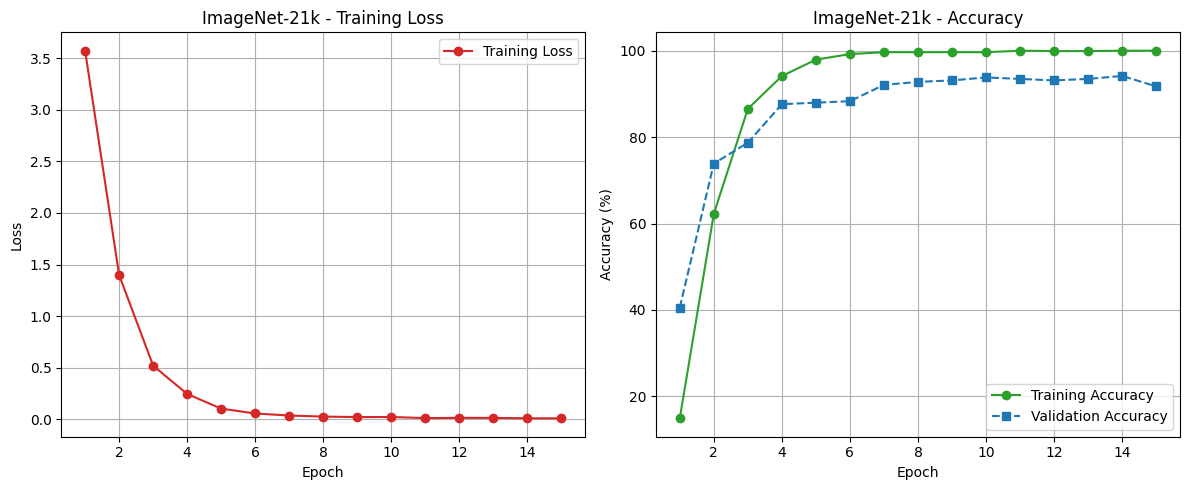


ImageNet-21k Results:
Test Accuracy: 93.78%
Test F1-Score: 0.9371
Test AUC-ROC: 0.9990

Training CLIP pretrained ViT
Train samples: 1160
Val samples: 291
Test samples: 225
Number of classes: 45
Class names: ['BIO - Actros_Philos' 'BIO - Cyclos' 'BIO - Evia' 'BOS - Altrua_Insignia'
 'BOS - Autogen_Teligen_Energen_Cognis' 'BOS - Contak Renewal 4'
 'BOS - Contak Renewal TR2' 'BOS - ContakTR_Discovery_Meridian_Pulsar Max'
 'BOS - Emblem' 'BOS - Ingenio' 'BOS - Proponent' 'BOS - Ventak Prizm'
 'BOS - Visionist' 'BOS - Vitality' 'MDT - AT500'
 'MDT - Adapta_Kappa_Sensia_Versa' 'MDT - Advisa' 'MDT - Azure'
 'MDT - C20_T20' 'MDT - C60 DR' 'MDT - Claria_Evera_Viva'
 'MDT - Concerto_Consulta_Maximo_Protecta_Secura' 'MDT - EnRhythm'
 'MDT - Insync III' 'MDT - Maximo' 'MDT - REVEAL' 'MDT - REVEAL LINQ'
 'MDT - Sigma' 'MDT - Syncra' 'MDT - Vita II' 'SOR - Elect'
 'SOR - Elect XS Plus' 'SOR - MiniSwing' 'SOR - Neway' 'SOR - Ovatio'
 'SOR - Reply' 'SOR - Rhapsody_Symphony' 'SOR - Thesis' 'STJ - Acce

Epoch 1/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=3.8068, Acc=2.84%]


Epoch [1/15]
Train Loss: 3.8906, Train Acc: 2.84%
Val Acc: 3.44%
--------------------------------------------------


Epoch 2/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=3.7215, Acc=2.41%]


Epoch [2/15]
Train Loss: 3.7933, Train Acc: 2.41%
Val Acc: 3.44%
--------------------------------------------------


...

Epoch [13/15]
Train Loss: 0.3333, Train Acc: 93.45%
Val Acc: 65.98%
--------------------------------------------------


Epoch 14/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=0.0822, Acc=94.40%]


Epoch [14/15]
Train Loss: 0.2760, Train Acc: 94.40%
Val Acc: 66.67%
--------------------------------------------------


Epoch 15/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=0.1218, Acc=95.26%]


Epoch [15/15]
Train Loss: 0.2559, Train Acc: 95.26%
Val Acc: 65.64%
--------------------------------------------------


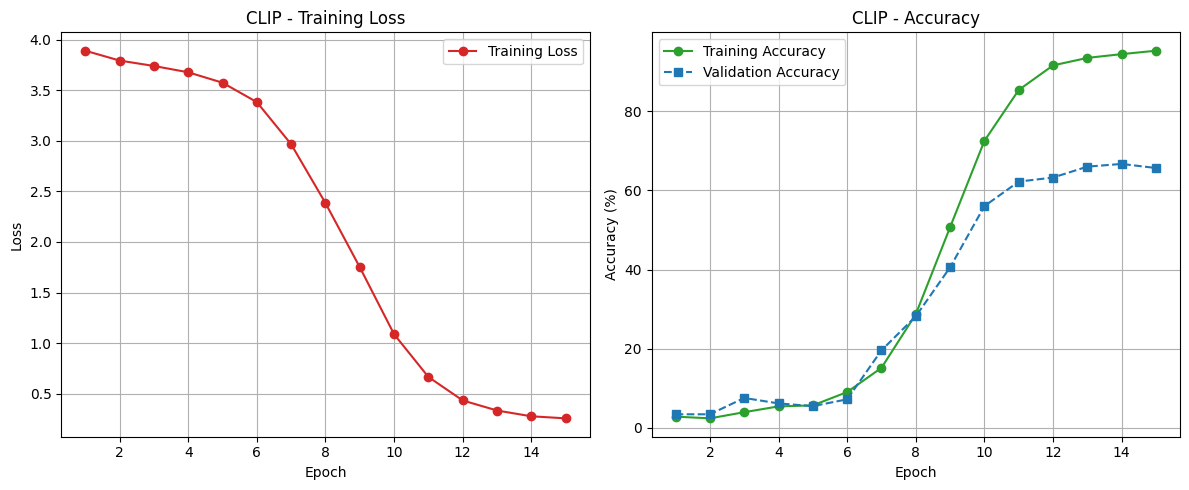


CLIP Results:
Test Accuracy: 63.11%
Test F1-Score: 0.6335
Test AUC-ROC: 0.9771

Training DINOv2 pretrained ViT
Train samples: 1160
Val samples: 291
Test samples: 225
Number of classes: 45
Class names: ['BIO - Actros_Philos' 'BIO - Cyclos' 'BIO - Evia' 'BOS - Altrua_Insignia'
 'BOS - Autogen_Teligen_Energen_Cognis' 'BOS - Contak Renewal 4'
 'BOS - Contak Renewal TR2' 'BOS - ContakTR_Discovery_Meridian_Pulsar Max'
 'BOS - Emblem' 'BOS - Ingenio' 'BOS - Proponent' 'BOS - Ventak Prizm'
 'BOS - Visionist' 'BOS - Vitality' 'MDT - AT500'
 'MDT - Adapta_Kappa_Sensia_Versa' 'MDT - Advisa' 'MDT - Azure'
 'MDT - C20_T20' 'MDT - C60 DR' 'MDT - Claria_Evera_Viva'
 'MDT - Concerto_Consulta_Maximo_Protecta_Secura' 'MDT - EnRhythm'
 'MDT - Insync III' 'MDT - Maximo' 'MDT - REVEAL' 'MDT - REVEAL LINQ'
 'MDT - Sigma' 'MDT - Syncra' 'MDT - Vita II' 'SOR - Elect'
 'SOR - Elect XS Plus' 'SOR - MiniSwing' 'SOR - Neway' 'SOR - Ovatio'
 'SOR - Reply' 'SOR - Rhapsody_Symphony' 'SOR - Thesis' 'STJ - Accent'
 '

Epoch 1/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=2.1729, Acc=19.40%]


Epoch [1/15]
Train Loss: 3.2409, Train Acc: 19.40%
Val Acc: 42.27%
--------------------------------------------------


Epoch 2/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=0.3367, Acc=68.71%]


Epoch [2/15]
Train Loss: 1.2213, Train Acc: 68.71%
Val Acc: 69.07%
--------------------------------------------------


...

Epoch [13/15]
Train Loss: 0.0098, Train Acc: 99.91%
Val Acc: 88.32%
--------------------------------------------------


Epoch 14/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=0.0042, Acc=99.91%] 


Epoch [14/15]
Train Loss: 0.0102, Train Acc: 99.91%
Val Acc: 87.97%
--------------------------------------------------


Epoch 15/15: 100%|██████████| 37/37 [00:21<00:00,  1.73it/s, Loss=0.0098, Acc=100.00%]


Epoch [15/15]
Train Loss: 0.0099, Train Acc: 100.00%
Val Acc: 85.91%
--------------------------------------------------


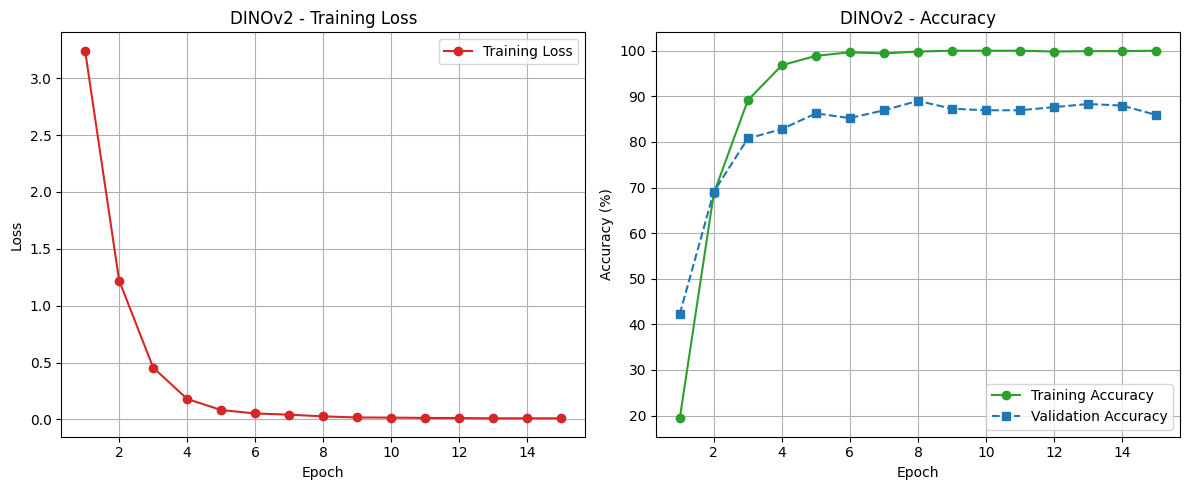


DINOv2 Results:
Test Accuracy: 88.89%
Test F1-Score: 0.8882
Test AUC-ROC: 0.9970

FINAL RESULTS COMPARISON - PACEMAKER DATASET
              Test Accuracy  Test F1-Score  Test AUC-ROC
ImageNet-21k        93.7778         0.9371        0.9990
CLIP                63.1111         0.6335        0.9771
DINOv2              88.8889         0.8882        0.9970


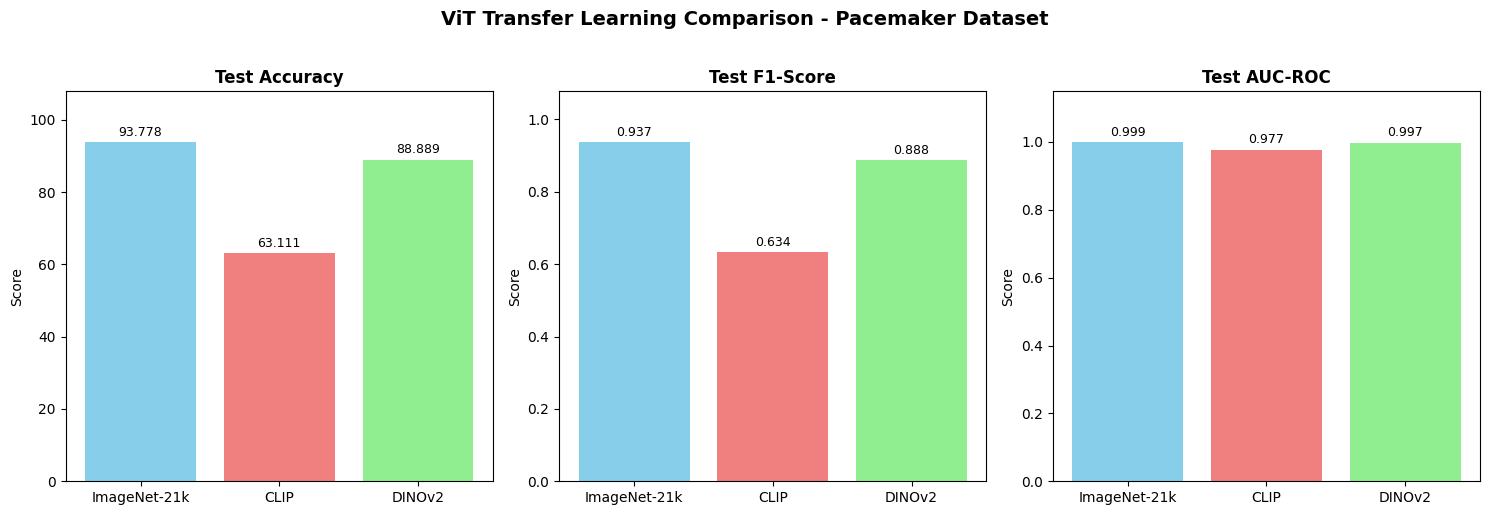


Training complete! Results saved to:
  - vit_pacemaker_results.csv
  - vit_pacemaker_comparison.png
  - Model weights: {imagenet-21k,clip,dinov2}_vit_pacemaker.pth


In [16]:
import gc
import torch
from torch.utils.data import DataLoader

def main():
    """Main function to run the experiments with Pacemaker dataset"""
    
    # Set device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    # Dataset path - adjust this to your pacemaker dataset location
    pacemaker_root = '/kaggle/input/pacemakers'  # Adjust path as needed
    
    # Create transforms
    train_transform, val_transform = create_transforms()
    clip_processor = create_clip_processor()
    
    # Results storage
    results = {}
    
    # Model configurations
    pretrain_types = ['ImageNet-21k','CLIP','DINOv2']
    
    for pretrain_type in pretrain_types:
        print(f"\n{'='*60}")
        print(f"Training {pretrain_type} pretrained ViT")
        print(f"{'='*60}")
        
        # Create datasets based on pretrain type
        if pretrain_type == 'CLIP':
            train_dataset, val_dataset, test_dataset = create_pacemaker_datasets(
                pretrain_type,
                pacemaker_root, 
                preprocess=clip_processor,
                val_split=0.2,
                random_state=42
            )
        else:
            # For ImageNet-21k and DINOv2, use standard transforms
            train_dataset, val_dataset, test_dataset = create_pacemaker_datasets(
                pretrain_type,
                pacemaker_root, 
                transform=train_transform,
                val_split=0.2,
                random_state=42
            )
            # Use val_transform for validation and test sets
            val_dataset.preprocess = val_transform
            test_dataset.preprocess = val_transform
        
        # Create data loaders
        train_loader = DataLoader(
            train_dataset, 
            batch_size=32, 
            shuffle=True, 
            num_workers=2,
            pin_memory=True if torch.cuda.is_available() else False
        )

        val_loader = DataLoader(
            val_dataset, 
            batch_size=32, 
            shuffle=False, 
            num_workers=2,
            pin_memory=True if torch.cuda.is_available() else False
        )
        test_loader = DataLoader(
            test_dataset, 
            batch_size=32, 
            shuffle=False, 
            num_workers=2,
            pin_memory=True if torch.cuda.is_available() else False
        )
        
        # Get number of classes
        num_classes = train_dataset.num_classes
        print(f"Number of classes: {num_classes}")
        print(f"Class names: {train_dataset.label_encoder.classes_}")
        
        # Create model
        model = ViTWithCustomHead('vit_base_patch16_224', num_classes, pretrain_type)

        # Train model
        trained_model, train_losses, train_accuracies, val_accuracies = train_model(
            model, train_loader, val_loader, 
            num_epochs=15, lr=2e-5, device=device
        )

        # Plot training curves
        plot_training_curves(train_losses, train_accuracies, val_accuracies, pretrain_type)
        
        # Evaluate on test set
        test_acc, test_f1, test_auc = evaluate_model(trained_model, test_loader, device)
        
        # Store results
        results[pretrain_type] = {
            'Test Accuracy': test_acc,
            'Test F1-Score': test_f1,
            'Test AUC-ROC': test_auc
        }
        
        # Save model
        torch.save(trained_model.state_dict(), f'{pretrain_type.lower()}_vit_pacemaker.pth')
        
        print(f"\n{pretrain_type} Results:")
        print(f"Test Accuracy: {test_acc:.2f}%")
        print(f"Test F1-Score: {test_f1:.4f}")
        print(f"Test AUC-ROC: {test_auc:.4f}")

        # Cleanup to free memory
        del model, trained_model
        del train_loader, val_loader, test_loader
        del train_dataset, val_dataset, test_dataset
        gc.collect()
        
        # Clear PyTorch cache
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    
    # Create comparison table
    print(f"\n{'='*80}")
    print("FINAL RESULTS COMPARISON - PACEMAKER DATASET")
    print(f"{'='*80}")
    
    results_df = pd.DataFrame(results).T
    print(results_df.round(4))
    
    # Save results to CSV
    results_df.to_csv('vit_pacemaker_results.csv')
    
    # Plot comparison
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    metrics = ['Test Accuracy', 'Test F1-Score', 'Test AUC-ROC']
    colors = ['skyblue', 'lightcoral', 'lightgreen']
    
    for i, metric in enumerate(metrics):
        values = [results[model][metric] for model in results.keys()]
        bars = axes[i].bar(results.keys(), values, color=colors)
        axes[i].set_title(metric, fontsize=12, fontweight='bold')
        axes[i].set_ylabel('Score', fontsize=10)
        axes[i].set_ylim([0, max(values) * 1.15])
        
        # Add value labels on bars
        for j, v in enumerate(values):
            axes[i].text(j, v + 0.01 * max(values), f'{v:.3f}', 
                        ha='center', va='bottom', fontsize=9)
    
    plt.suptitle('ViT Transfer Learning Comparison - Pacemaker Dataset', 
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('vit_pacemaker_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\n" + "="*80)
    print("Training complete! Results saved to:")
    print("  - vit_pacemaker_results.csv")
    print("  - vit_pacemaker_comparison.png")
    print("  - Model weights: {imagenet-21k,clip,dinov2}_vit_pacemaker.pth")
    print("="*80)

if __name__ == "__main__":
    main()